# m09 - Multi-Output MLP on the GPU: A Small Set of Sweeps

A PyTorch MLP that predicts all ten GAEZ indices at once from the 14 physical drivers, scored with the honest pixel-grouped CV
(5 folds x 2 repeats). Base configuration: two hidden layers (128, 64), SiLU, AdamW, 60 epochs, batch 512, one-cycle learning
rate, MSE on z-scored targets. Each line below changes one thing against that base and reports mean R$^2$ over the ten crops.

1. Architecture (depth x width)
2. Regularisation, normalisation, loss
3. Averaging several seeds, and the gap to the tree models of m01

In [1]:
import torch  # noqa: F401  - keep first (see exp_lib docstring)
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)
import exp_torch as T
print('device:', T.DEVICE, torch.cuda.get_device_name(0) if T.DEVICE == 'cuda' else '')

device: cuda NVIDIA GeForce RTX 5060


In [2]:
df = E.load_table()
targets = {c: df[E.target_col(c)].to_numpy() for c in E.CROPS}   # GAEZ v5 at 1 km (E.TARGET_RES)
BASE = dict(hidden=(128, 64), act="silu", norm=None, dropout=0.0, lr=3e-3, weight_decay=1e-4, epochs=60, batch_size=512, loss="mse", input_noise=0.0)
log = []

def run(section, name, cfg=None, **kw):
    res, _ = T.cv_multioutput(df, targets, {**BASE, **(cfg or {})}, **kw)
    log.append({"section": section, "setting": name, "r2": res["r2"].mean(), "spearman": res["spearman"].mean(),
                "rmse": res["rmse"].mean(), "seconds_per_repeat": res["fit_seconds"].iloc[0]})
    print(f"[{section}] {name:28s} R2={log[-1]['r2']:.3f}  rho={log[-1]['spearman']:.3f}  ({log[-1]['seconds_per_repeat']:.0f}s/repeat)", flush=True)

run("base", "128-64 (base)")

[base] 128-64 (base)                R2=0.784  rho=0.884  (9s/repeat)


## 1. Architecture

In [3]:
for hidden in [(64,), (128,), (64, 64), (128, 128), (64, 64, 64), (128, 128, 128)]:
    run("architecture", "-".join(map(str, hidden)), dict(hidden=hidden))

[architecture] 64                           R2=0.742  rho=0.859  (4s/repeat)


[architecture] 128                          R2=0.752  rho=0.865  (4s/repeat)


[architecture] 64-64                        R2=0.781  rho=0.883  (7s/repeat)


[architecture] 128-128                      R2=0.787  rho=0.886  (7s/repeat)


[architecture] 64-64-64                     R2=0.788  rho=0.887  (8s/repeat)


[architecture] 128-128-128                  R2=0.790  rho=0.889  (8s/repeat)


## 2. Regularisation, normalisation, loss

In [4]:
run("regularisation", "dropout 0.2", dict(dropout=0.2))
run("regularisation", "weight decay 1e-2", dict(weight_decay=1e-2))
run("regularisation", "input noise 0.1", dict(input_noise=0.1))
run("norm / activation", "layer norm + silu", dict(norm="layer"))
run("norm / activation", "relu", dict(act="relu"))
run("norm / activation", "layer norm + relu", dict(norm="layer", act="relu"))
run("loss", "huber (delta 1)", dict(loss="huber", huber_delta=1.0))

[regularisation] dropout 0.2                  R2=0.781  rho=0.883  (7s/repeat)


[regularisation] weight decay 1e-2            R2=0.784  rho=0.884  (7s/repeat)


[regularisation] input noise 0.1              R2=0.777  rho=0.880  (7s/repeat)


[norm / activation] layer norm + silu            R2=0.798  rho=0.892  (8s/repeat)


[norm / activation] relu                         R2=0.794  rho=0.890  (7s/repeat)


[norm / activation] layer norm + relu            R2=0.796  rho=0.892  (8s/repeat)


[loss] huber (delta 1)              R2=0.786  rho=0.886  (7s/repeat)


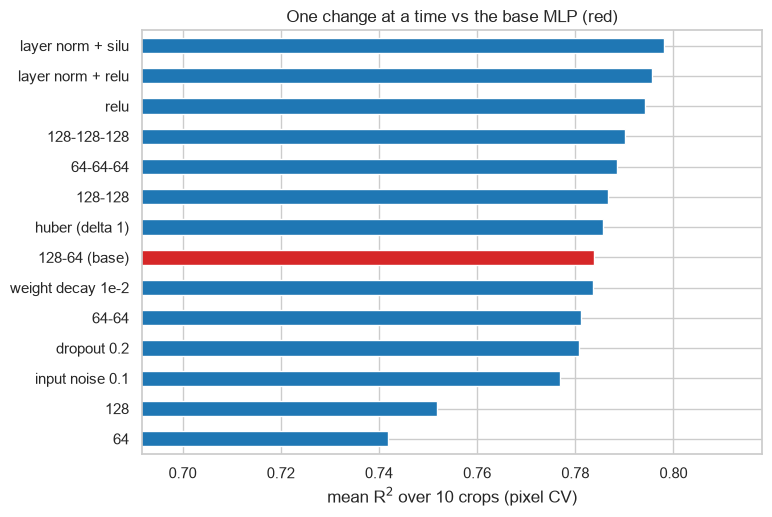

,section,setting,r2,spearman,rmse
0,base,128-64 (base),0.784,0.884,958.502
1,architecture,64,0.742,0.859,1050.157
2,architecture,128,0.752,0.865,1028.535
3,architecture,64-64,0.781,0.883,964.212
4,architecture,128-128,0.787,0.886,951.000
5,architecture,64-64-64,0.788,0.887,948.401
6,architecture,128-128-128,0.790,0.889,942.603
7,regularisation,dropout 0.2,0.781,0.883,965.374
8,regularisation,weight decay 1e-2,0.784,0.884,958.943
9,regularisation,input noise 0.1,0.777,0.880,974.142


In [5]:
sweep = pd.DataFrame(log)
E.save_table(sweep.round(4), "m09_mlp_sweeps")
fig, ax = plt.subplots(figsize=(8, 5.5))
s = sweep.set_index("setting")["r2"].sort_values()
s.plot.barh(ax=ax, color=["tab:red" if k == "128-64 (base)" else "tab:blue" for k in s.index])
ax.set(xlabel="mean R$^2$ over 10 crops (pixel CV)", ylabel="", xlim=(max(0, s.min() - 0.05), s.max() + 0.02), title="One change at a time vs the base MLP (red)")
E.save_fig(fig, "m09_mlp_sweeps")
plt.show()
sweep[["section", "setting", "r2", "spearman", "rmse"]].round(3)

## 3. Averaging seeds and the gap to the tree models

In [6]:
res1, _ = T.cv_multioutput(df, targets, BASE, n_seeds=1)
res3, _ = T.cv_multioutput(df, targets, BASE, n_seeds=3)
wide = {**BASE, "hidden": (256, 256), "dropout": 0.1, "weight_decay": 1e-3, "input_noise": 0.1}
res3w, oof3w = T.cv_multioutput(df, targets, wide, n_seeds=3)
final = {"MLP base, 1 seed": res1, "MLP base, 3-seed average": res3, "MLP wide + regularised, 3-seed average": res3w}
ref = pd.read_csv(E.RESULTS_DIR / "m01_baselines_raw.csv")
ref = ref[ref.scheme == "pixel"].groupby("model")[["r2", "spearman", "rmse"]].mean()
tab = pd.DataFrame({k: v[["r2", "spearman", "rmse"]].mean() for k, v in final.items()}).T
tab = pd.concat([tab, ref.loc[["et", "hgb", "xgb"]].rename(index=lambda m: f"{m} (m01)")])
E.save_table(tab.round(4), "m09_mlp_vs_trees", index=True)
tab.round(3)

,r2,spearman,rmse
"MLP base, 1 seed",0.784,0.884,958.502
"MLP base, 3-seed average",0.788,0.887,948.225
"MLP wide + regularised, 3-seed average",0.788,0.886,949.395
et (m01),0.820,0.902,873.098
hgb (m01),0.808,0.897,901.163
xgb (m01),0.809,0.896,899.598


In [7]:
oof_df = df[["grid_id"]].copy()
for j, c in enumerate(E.CROPS):
    oof_df[f"mlp3__{c}"] = oof3w[:, :, j].mean(axis=0)
print(E.save_oof(oof_df, "m09_mlp_oof_pixel"))

D:\Softwares\AnacondaProjects\GeoSuitability_AI_Analytics\datasets\processed\experiments\m09_mlp_oof_pixel.parquet
